# Fully ablated context relevance vs LLM judges

Cache-only comparison on the same traces and Qwen3.5 / Llama 3.1 / Llama 3.2 models as `context-relevance-plots.ipynb`. Fully ablated context relevance uses **average log likelihood per context**; its lowest-scoring step is the error candidate (earliest in a tie). Qwen judges use full-run CSVs; Llama judges use cached responses. Invalid responses count as wrong. Exclude the same invalid Dyck trace from both sources.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import make_scorer
from sklearn.model_selection import TunedThresholdClassifierCV

from experiment_setup import dc_pmi, llm_critic
from experiment_setup.benchmarks import load_examples
from experiment_setup.judge_metrics import score as judge_score

CACHE, RUNS = Path('cache'), Path('runs')
MODELS = {
    'Qwen3.5-4B': ('Qwen/Qwen3.5-4B', 'qwen35_4b'),
    'Qwen3.5-9B': ('Qwen/Qwen3.5-9B', 'qwen35_9b'),
    'Qwen3.5-27B': ('Qwen/Qwen3.5-27B', 'qwen35_27b'),
    'Llama3.1-8B': ('meta-llama/Llama-3.1-8B-Instruct', 'llama31_8b'),
    'Llama3.2-3B': ('meta-llama/Llama-3.2-3B-Instruct', 'llama32_3b'),
}
BENCHMARKS = ['MR-GSM8K', 'BIG-Bench-Mistake', 'ProcessBench']
KEYS = ['benchmark', 'task', 'uid']
METRIC = 'dc_pmi_generic_domain'
CR_LABEL = 'Fully ablated context relevance'
METHODS = ['LLM judge', CR_LABEL]
examples = [e for task in load_examples().values() for e in task
            if not (e.benchmark == 'BIG-Bench-Mistake' and e.task == 'dyck_languages' and e.uid == '52')]
assert len(examples) == 8584
expected = pd.DataFrame([dict(benchmark=e.benchmark, task=e.task, uid=str(e.uid), label=e.label)
                         for e in examples])
assert not expected.duplicated(KEYS).any()

## Decision rule

For each trace, select the step with the lowest **fully ablated context relevance** (earliest in a tie). **Error-step detection accuracy** is the fraction of *erroneous* traces whose selected step is the annotated first error; it does not use a threshold. For **overall accuracy**, predict the selected step only when its negative context relevance is at least the fitted threshold, otherwise predict NONE. This is exact first-error-or-NONE accuracy over *all* traces, not binary error-presence accuracy.

`TunedThresholdClassifierCV` is from **scikit-learn**, not SciPy. A custom scorer accounts for wrong locations (they are wrong regardless of the binary decision). The threshold is tuned **separately for each benchmark and model** over every distinct candidate evidence score plus all/none endpoints, giving the optimal in-sample threshold. Tuning and evaluation use the same traces (`cv='prefit'`): these are **optimistic in-sample comparisons**, not held-out estimates. The prefit estimator only passes the candidate score through; it does not learn from the labels.

In [2]:
def exact_location_accuracy(y_true, y_pred, *, candidate_correct):
    predicted_error = np.asarray(y_pred, dtype=bool)
    actual_error = np.asarray(y_true, dtype=bool)
    return np.mean((~predicted_error & ~actual_error) |
                   (predicted_error & candidate_correct))


def select_candidates(scores):
    evidence = dc_pmi.error_evidence_score(scores, METRIC)
    candidates = scores.assign(evidence=evidence).loc[
        evidence.groupby([scores[k] for k in KEYS], sort=False).idxmax()
    ].copy()
    candidates['candidate_correct'] = candidates.step.eq(candidates.label)
    return candidates


def tune_accuracy(candidates):
    evidence = candidates.evidence.to_numpy()
    truth = candidates.label.notna().to_numpy()
    correct = candidates.candidate_correct.to_numpy(dtype=bool)
    X = evidence.reshape(-1, 1)
    thresholds = np.unique(np.r_[np.nextafter(evidence.min(), -np.inf),
                                 evidence,
                                 np.nextafter(evidence.max(), np.inf)])
    estimator = dc_pmi.RawScoreClassifier().fit(X, truth)
    tuned = TunedThresholdClassifierCV(
        estimator, cv='prefit', refit=False, response_method='decision_function',
        scoring=make_scorer(exact_location_accuracy, candidate_correct=correct),
        thresholds=thresholds,
    ).fit(X, truth)
    return tuned.best_score_, tuned.best_threshold_

In [3]:
def load_judge(model_id, stem, selected_examples):
    if stem.startswith('qwen35_'):
        frame = pd.read_csv(RUNS / f'llm_judge_{stem}_full_arm.csv',
                            dtype={'uid': str}, usecols=[*KEYS, 'label', 'prediction', 'parse_error'])
    else:
        frame = llm_critic.load_run(selected_examples, model_id=model_id,
                                    cache_path=CACHE / f'llm_judge_{stem}_arm.sqlite')
        frame['uid'] = frame.uid.astype(str)
    return frame


rows = []
for model, (model_id, stem) in MODELS.items():
    scores = dc_pmi.load_run(examples, model_id=model_id, average_ll=True,
                              cache_path=CACHE / f'dc_pmi_{stem}_arm.sqlite')
    scores['uid'] = scores.uid.astype(str)
    assert len(scores[KEYS].drop_duplicates()) == len(expected)
    assert scores[KEYS].drop_duplicates().merge(expected[KEYS], on=KEYS, validate='one_to_one').shape[0] == len(expected)
    judge = expected[KEYS].merge(load_judge(model_id, stem, examples), on=KEYS,
                                 how='left', validate='one_to_one', indicator=True)
    assert judge._merge.eq('both').all()
    judge = judge.drop(columns='_merge')
    assert judge.label.fillna(-1).eq(expected.label.fillna(-1)).all()
    for benchmark in BENCHMARKS:
        judge_group = judge.loc[judge.benchmark == benchmark]
        judge_result = judge_score(judge_group)
        rows.append(dict(benchmark=benchmark, model=model, method='LLM judge',
                         error_accuracy=judge_result['error_accuracy'],
                         overall_accuracy=judge_result['accuracy'], threshold=np.nan,
                         n=judge_result['n']))
        candidates = select_candidates(scores.loc[scores.benchmark == benchmark])
        assert len(candidates) == len(judge_group)
        errors = candidates.label.notna()
        accuracy, threshold = tune_accuracy(candidates)
        rows.append(dict(benchmark=benchmark, model=model, method=CR_LABEL,
                         error_accuracy=candidates.loc[errors, 'candidate_correct'].mean(),
                         overall_accuracy=accuracy, threshold=threshold, n=len(candidates)))
comparison = pd.DataFrame(rows)
display(comparison.round(3))

2026-11-08 18:15:24 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_4b_arm.sqlite


2026-11-08 18:15:31 INFO experiment_setup: Loaded records


2026-11-08 18:15:35 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_9b_arm.sqlite


2026-11-08 18:15:41 INFO experiment_setup: Loaded records


2026-11-08 18:15:45 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_27b_arm.sqlite


2026-11-08 18:15:51 INFO experiment_setup: Loaded records


2026-11-08 18:15:54 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_llama31_8b_arm.sqlite


2026-11-08 18:16:01 INFO experiment_setup: Loaded records


2026-11-08 18:16:18 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_llama32_3b_arm.sqlite


2026-11-08 18:16:24 INFO experiment_setup: Loaded records


,benchmark,model,method,error_accuracy,overall_accuracy,threshold,n
0,MR-GSM8K,Qwen3.5-4B,LLM judge,0.473,0.554,NaN,2999
1,MR-GSM8K,Qwen3.5-4B,Fully ablated context relevance,0.225,0.476,0.320,2999
2,BIG-Bench-Mistake,Qwen3.5-4B,LLM judge,0.254,0.246,NaN,2185
3,BIG-Bench-Mistake,Qwen3.5-4B,Fully ablated context relevance,0.045,0.219,0.227,2185
4,ProcessBench,Qwen3.5-4B,LLM judge,0.396,0.414,NaN,3400
5,ProcessBench,Qwen3.5-4B,Fully ablated context relevance,0.236,0.347,1.465,3400
6,MR-GSM8K,Qwen3.5-9B,LLM judge,0.439,0.635,NaN,2999
7,MR-GSM8K,Qwen3.5-9B,Fully ablated context relevance,0.228,0.476,-0.195,2999
8,BIG-Bench-Mistake,Qwen3.5-9B,LLM judge,0.247,0.246,NaN,2185
9,BIG-Bench-Mistake,Qwen3.5-9B,Fully ablated context relevance,0.042,0.219,-0.122,2185


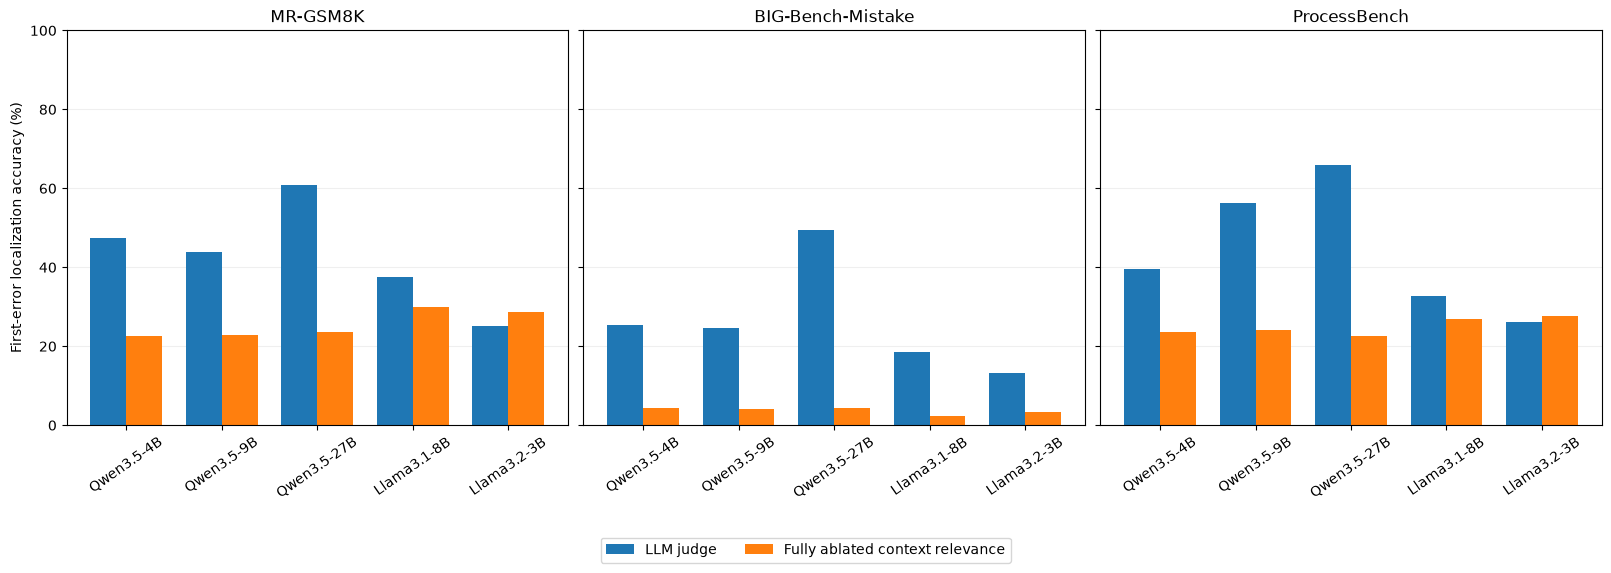

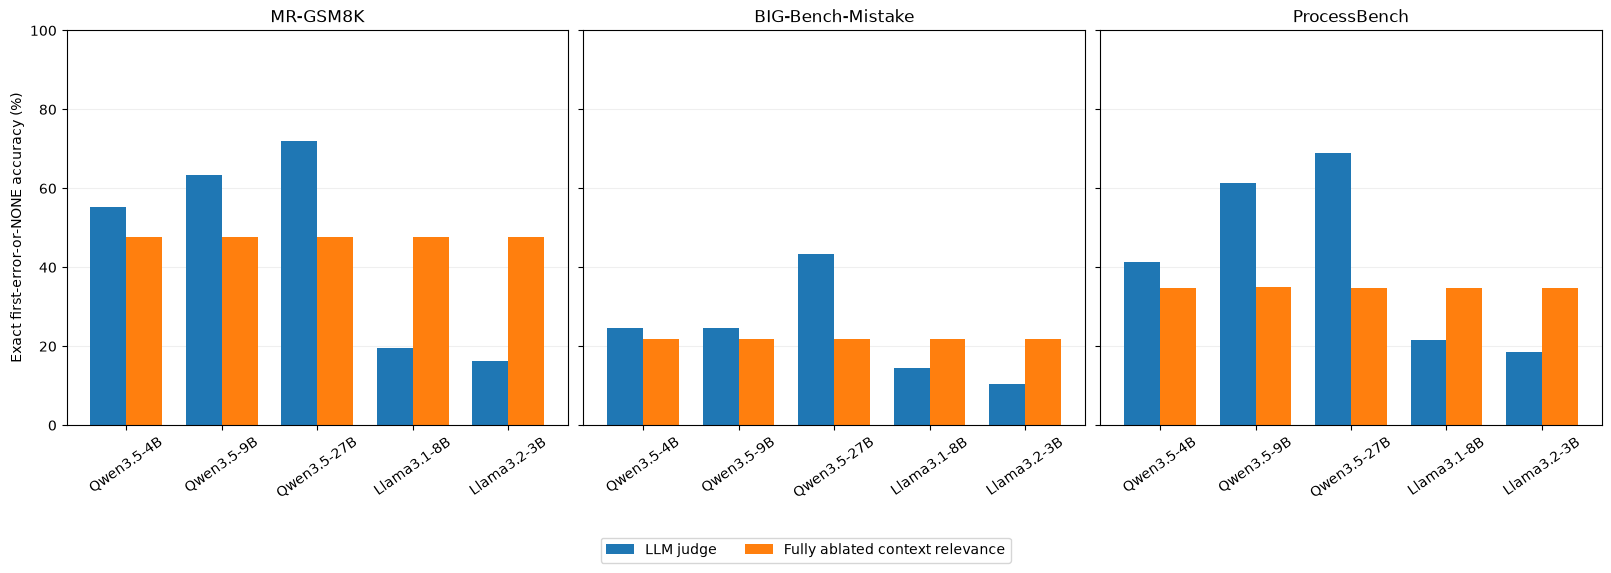

In [4]:
# Thesis-ready comparisons. All bars use matched traces and exact-location accuracy.
out = Path('../thesis/chapters/results')
for column, filename, ylabel in [
    ('error_accuracy', 'judge-vs-context-error.png', 'First-error localization accuracy (%)'),
    ('overall_accuracy', 'judge-vs-context-overall.png', 'Exact first-error-or-NONE accuracy (%)'),
]:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True, constrained_layout=True)
    for ax, benchmark in zip(axes, BENCHMARKS):
        values = (comparison.loc[comparison.benchmark == benchmark]
                  .pivot(index='model', columns='method', values=column)
                  .reindex(index=MODELS, columns=METHODS))
        values.mul(100).plot.bar(ax=ax, rot=35, legend=False, width=.75)
        ax.set(title=benchmark, xlabel='', ylabel=ylabel, ylim=(0, 100))
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
    fig.legend(axes[0].get_legend_handles_labels()[0], METHODS,
               loc='lower center', ncol=2, bbox_to_anchor=(.5, -.13))
    fig.savefig(out / filename, dpi=220, bbox_inches='tight')
    plt.show()